# 56 · From our .npz episodes to the LeRobotDataset layout (Parquet + MP4 + metadata)

In [1]:
import os, json, shutil, numpy as np, pandas as pd, imageio, pyarrow as pa, pyarrow.parquet as pq, matplotlib.pyplot as plt
from vlacourse import list_episodes, load_episode, load_meta

SRC = os.path.abspath("../data/tabletop_panda_v1")
DST = os.path.abspath("../data/lerobot/tabletop_panda_v1")
STATE_NAMES = ["ee_x", "ee_y", "ee_z", "ee_qw", "ee_qx", "ee_qy", "ee_qz", "gripper_width"]

def stats_of(x):
    x = np.asarray(x, np.float64)
    return {"mean": x.mean(0).tolist(), "std": x.std(0).tolist(), "min": x.min(0).tolist(), "max": x.max(0).tolist(), "count": [len(x)]}

def export_lerobot_v21(src, dst, repo_id="local/tabletop_panda_v1", fps=10, chunks_size=1000):
    meta = load_meta(src); cams = meta["cameras"]; h, w = meta["image_size"]
    if os.path.exists(dst):
        shutil.rmtree(dst)
    tasks, ep_rows, ep_stats, index, all_state, all_act = {}, [], [], 0, [], []
    for ei, path in enumerate(list_episodes(src)):
        ep = load_episode(path); T = len(ep["action"]); chunk = ei // chunks_size
        tid = tasks.setdefault(ep["instruction"], len(tasks))
        df = pd.DataFrame({
            "observation.state": list(ep["state"].astype(np.float32)),
            "action": list(ep["action"].astype(np.float32)),
            "timestamp": (np.arange(T) / fps).astype(np.float32),
            "frame_index": np.arange(T, dtype=np.int64),
            "episode_index": np.full(T, ei, dtype=np.int64),
            "index": np.arange(index, index + T, dtype=np.int64),
            "task_index": np.full(T, tid, dtype=np.int64),
        })
        os.makedirs(f"{dst}/data/chunk-{chunk:03d}", exist_ok=True)
        pq.write_table(pa.Table.from_pandas(df, preserve_index=False), f"{dst}/data/chunk-{chunk:03d}/episode_{ei:06d}.parquet")
        for c in cams:
            vdir = f"{dst}/videos/chunk-{chunk:03d}/observation.images.{c}"; os.makedirs(vdir, exist_ok=True)
            imageio.mimsave(f"{vdir}/episode_{ei:06d}.mp4", list(ep[c]), fps=fps, codec="libx264", quality=8, macro_block_size=1)
        ep_rows.append({"episode_index": ei, "tasks": [ep["instruction"]], "length": T})
        ep_stats.append({"episode_index": ei, "stats": {"observation.state": stats_of(ep["state"]), "action": stats_of(ep["action"])}})
        all_state.append(ep["state"]); all_act.append(ep["action"]); index += T
    feats = {f"observation.images.{c}": {"dtype": "video", "shape": [h, w, 3], "names": ["height", "width", "channels"],
                                         "info": {"video.fps": fps, "video.codec": "h264", "video.pix_fmt": "yuv420p"}} for c in cams}
    feats.update({"observation.state": {"dtype": "float32", "shape": [8], "names": STATE_NAMES},
                  "action": {"dtype": "float32", "shape": [7], "names": meta["action_names"]},
                  "timestamp": {"dtype": "float32", "shape": [1], "names": None},
                  "frame_index": {"dtype": "int64", "shape": [1], "names": None}, "episode_index": {"dtype": "int64", "shape": [1], "names": None},
                  "index": {"dtype": "int64", "shape": [1], "names": None}, "task_index": {"dtype": "int64", "shape": [1], "names": None}})
    n_ep = len(ep_rows)
    info = {"codebase_version": "v2.1", "robot_type": "franka_panda_mujoco", "total_episodes": n_ep, "total_frames": index,
            "total_tasks": len(tasks), "total_videos": n_ep * len(cams), "total_chunks": (n_ep - 1) // chunks_size + 1, "chunks_size": chunks_size,
            "fps": fps, "splits": {"train": f"0:{n_ep}"},
            "data_path": "data/chunk-{episode_chunk:03d}/episode_{episode_index:06d}.parquet",
            "video_path": "videos/chunk-{episode_chunk:03d}/{video_key}/episode_{episode_index:06d}.mp4", "features": feats}
    os.makedirs(f"{dst}/meta", exist_ok=True)
    json.dump(info, open(f"{dst}/meta/info.json", "w"), indent=2)
    with open(f"{dst}/meta/tasks.jsonl", "w") as f:
        for t, i in tasks.items():
            f.write(json.dumps({"task_index": i, "task": t}) + "\n")
    with open(f"{dst}/meta/episodes.jsonl", "w") as f:
        for r in ep_rows:
            f.write(json.dumps(r) + "\n")
    with open(f"{dst}/meta/episodes_stats.jsonl", "w") as f:
        for r in ep_stats:
            f.write(json.dumps(r) + "\n")
    json.dump({"observation.state": stats_of(np.concatenate(all_state)), "action": stats_of(np.concatenate(all_act))}, open(f"{dst}/meta/stats.json", "w"), indent=1)
    return info

In [2]:
info = export_lerobot_v21(SRC, DST)
print(f"{info['total_episodes']} episodes, {info['total_frames']} frames, {info['total_tasks']} tasks, {info['total_videos']} videos")
for root, dirs, files in os.walk(DST):
    depth = root[len(DST):].count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(root) + "/", f"({len(files)} files)" if files else "")

200 episodes, 8420 frames, 12 tasks, 400 videos
tabletop_panda_v1/ 
  data/ 
    chunk-000/ (200 files)
  meta/ (5 files)
  videos/ 
    chunk-000/ 
      observation.images.front/ (200 files)
      observation.images.wrist/ (200 files)


In [3]:
size = lambda d: sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(d) for f in fs) / 1e6
print(f"npz (compressed raw frames): {size(SRC):.0f} MB   LeRobot (parquet + h264 video): {size(DST):.0f} MB")

npz (compressed raw frames): 166 MB   LeRobot (parquet + h264 video): 34 MB


                                                                   0  \
observation.state  [0.5545, -0.0, 0.521102, 0.0, 0.707142, 0.7070...   
action             [-0.009477, 0.00091, -0.041043, 0.0, 0.0, 0.3,...   
timestamp                                                        0.0   
frame_index                                                        0   
episode_index                                                      3   
index                                                            151   
task_index                                                         3   

                                                                   1  \
observation.state  [0.551708, 0.000226, 0.502965, -0.002645, 0.66...   
action             [-0.009477, 0.00091, -0.041043, 0.0, 0.0, 0.07...   
timestamp                                                        0.1   
frame_index                                                        1   
episode_index                                                  

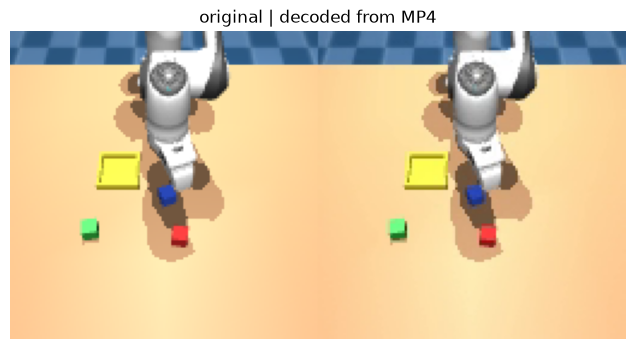

In [4]:
df = pd.read_parquet(f"{DST}/data/chunk-000/episode_000003.parquet")
print(df.head(3).T)
reader = imageio.get_reader(f"{DST}/videos/chunk-000/observation.images.front/episode_000003.mp4")
frame10 = reader.get_data(10); original = load_episode(list_episodes(SRC)[3])["front"][10]
print(f"video frame 10 vs original: mean abs pixel error {np.abs(frame10.astype(int) - original.astype(int)).mean():.2f} (lossy h264)")
plt.figure(figsize=(8, 4)); plt.imshow(np.hstack([original, frame10])); plt.axis("off"); plt.title("original | decoded from MP4"); plt.show()

In [5]:
tasks = pd.read_json(f"{DST}/meta/tasks.jsonl", lines=True)
print(tasks)
delta = [-1, 0, 1, 2]
t = 5
window = df.set_index("frame_index").loc[[max(0, t + d) for d in delta], "action"]
print("delta-timestamp query (LeRobot's 'delta_timestamps'): actions at t-1, t, t+1, t+2 ->\n", np.stack(window.values).round(3))

    task_index                                   task
0            0  stack the green cube on the blue cube
1            1   put the blue cube in the yellow tray
2            2  stack the blue cube on the green cube
3            3    stack the blue cube on the red cube
4            4  put the green cube in the yellow tray
5            5   stack the red cube on the green cube
6            6                   pick up the red cube
7            7    put the red cube in the yellow tray
8            8                 pick up the green cube
9            9                  pick up the blue cube
10          10   stack the green cube on the red cube
11          11    stack the red cube on the blue cube
delta-timestamp query (LeRobot's 'delta_timestamps'): actions at t-1, t, t+1, t+2 ->
 [[-0.009  0.001 -0.041  0.     0.     0.     0.   ]
 [-0.009  0.001 -0.041  0.     0.     0.     0.   ]
 [-0.009  0.001 -0.041  0.     0.     0.     0.   ]
 [-0.009  0.001 -0.041  0.     0.     0.     0.   ]]
